# Task 5.2: Local Evaluation and Error Analysis

## 1) Setup


In [1]:
from pathlib import Path
import ast

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, classification_report
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 160)

cwd = Path.cwd().resolve()
candidates = [cwd] + list(cwd.parents[:5])
PROJECT_ROOT = None
for c in candidates:
    if (c / "data" / "raw" / "dontpatronizeme_pcl.tsv").exists():
        PROJECT_ROOT = c
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find project root with data/raw/dontpatronizeme_pcl.tsv")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
BESTMODEL_DIR = PROJECT_ROOT / "BestModel"
DEV_PRED_PATH = BESTMODEL_DIR / "dev final.txt"
TEST_PRED_PATH = BESTMODEL_DIR / "test final.txt"

if not DEV_PRED_PATH.exists():
    raise FileNotFoundError(f"Missing dev prediction file: {DEV_PRED_PATH}")
if not TEST_PRED_PATH.exists():
    raise FileNotFoundError(f"Missing test prediction file: {TEST_PRED_PATH}")

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Using dev predictions:", DEV_PRED_PATH)
print("Using test predictions:", TEST_PRED_PATH)


PROJECT_ROOT: D:\D Documents\Imperial\Natural Language Processing\NLP_Coursework3\NLP_Coursework3
Using predictions: D:\D Documents\Imperial\Natural Language Processing\NLP_Coursework3\NLP_Coursework3\BestModel\dev.txt


## 2) Load Official Dev Data and Predictions


In [2]:
def parse_integer_identifier(raw_identifier):
    cleaned_identifier = str(raw_identifier).replace("@@", "").strip()
    return int(cleaned_identifier) if cleaned_identifier.isdigit() else None


def load_labelled_pcl_dataset(dataset_path: Path) -> pd.DataFrame:
    parsed_rows = []
    with dataset_path.open("r", encoding="utf-8", errors="replace") as file_handle:
        for text_line in file_handle:
            if text_line.startswith("---") or text_line.startswith("The Don"):
                continue
            cleaned_line = text_line.rstrip("\n")
            if not cleaned_line:
                continue
            columns = cleaned_line.split("\t")
            if len(columns) != 6:
                continue
            paragraph_id, article_id, keyword, country_code, paragraph_text, ordinal_label = columns
            parsed_paragraph_id = parse_integer_identifier(paragraph_id)
            if parsed_paragraph_id is None:
                continue
            parsed_rows.append(
                {
                    "par_id": parsed_paragraph_id,
                    "text": str(paragraph_text),
                    "keyword": str(keyword),
                    "country": str(country_code),
                    "label_ordinal": int(ordinal_label),
                }
            )
    df = pd.DataFrame(parsed_rows)
    df["label_bin"] = (df["label_ordinal"] >= 2).astype(int)
    return df

full_df = load_labelled_pcl_dataset(RAW_DIR / "dontpatronizeme_pcl.tsv")
dev_ids = pd.read_csv(RAW_DIR / "dev_semeval_parids-labels.csv")
dev_ids["label_official_bin"] = dev_ids["label"].apply(lambda s: 1 if sum(ast.literal_eval(s)) > 0 else 0)

dev_df = dev_ids[["par_id", "label_official_bin"]].merge(full_df, on="par_id", how="left", validate="one_to_one")
if dev_df["text"].isna().any():
    raise ValueError("Missing text rows after merge")

dev_pred_df = pd.read_csv(DEV_PRED_PATH, header=None, names=["pred"])
if len(dev_pred_df) != len(dev_df):
    raise ValueError(f"Prediction length mismatch: preds={len(dev_pred_df)}, dev={len(dev_df)}")
if not set(dev_pred_df["pred"].astype(int).unique()).issubset({0, 1}):
    raise ValueError("Dev prediction file must contain only 0/1 labels")

test_pred_df = pd.read_csv(TEST_PRED_PATH, header=None, names=["pred"])
test_input_df = pd.read_csv(RAW_DIR / "task4_test.tsv", sep="\t", header=None)
if len(test_pred_df) != len(test_input_df):
    raise ValueError(
        f"Test prediction length mismatch: preds={len(test_pred_df)}, official_test={len(test_input_df)}"
    )
if not set(test_pred_df["pred"].astype(int).unique()).issubset({0, 1}):
    raise ValueError("Test prediction file must contain only 0/1 labels")

analysis_df = dev_df.copy()
analysis_df["pred"] = dev_pred_df["pred"].astype(int)
analysis_df["correct"] = (analysis_df["pred"] == analysis_df["label_official_bin"]).astype(int)
analysis_df["token_count"] = analysis_df["text"].fillna("").str.split().str.len()

print("Dev rows:", len(analysis_df))
print("Test rows:", len(test_pred_df))
analysis_df[["par_id", "label_official_bin", "pred", "token_count"]].head()


Rows: 2094


,par_id,label_official_bin,pred,token_count
0,4046,1,0,85
1,1279,1,1,38
2,8330,1,0,16
3,4063,1,1,42
4,4089,1,0,70


## 3) Local Evaluation A: Core Metrics + Confusion Matrix


Positive-class F1: 0.630872
Precision (PCL=1): 0.568548
Recall (PCL=1):    0.708543

Classification report:

              precision    recall  f1-score   support

           0     0.9686    0.9435    0.9559      1895
           1     0.5685    0.7085    0.6309       199

    accuracy                         0.9212      2094
   macro avg     0.7686    0.8260    0.7934      2094
weighted avg     0.9306    0.9212    0.9250      2094



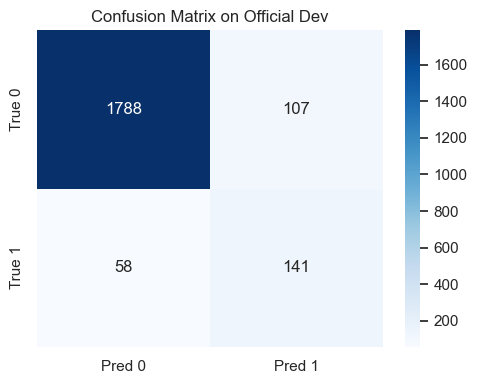

,tn,fp,fn,tp
0,1788,107,58,141


In [3]:
y_true = analysis_df["label_official_bin"].to_numpy()
y_pred = analysis_df["pred"].to_numpy()

f1_pos = f1_score(y_true, y_pred, pos_label=1)
prec_pos = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
rec_pos = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()
print(f"Positive-class F1: {f1_pos:.6f}")
print(f"Precision (PCL=1): {prec_pos:.6f}")
print(f"Recall (PCL=1):    {rec_pos:.6f}")
print("\nClassification report:\n")
print(classification_report(y_true, y_pred, digits=4, zero_division=0))

cm_df = pd.DataFrame(cm, index=["True 0", "True 1"], columns=["Pred 0", "Pred 1"])
plt.figure(figsize=(5, 4))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix on Official Dev")
plt.tight_layout()
plt.show()

pd.DataFrame({"tn": [tn], "fp": [fp], "fn": [fn], "tp": [tp]})


## 4) Error Analysis: False Positives and False Negatives


In [4]:
false_positives = analysis_df[(analysis_df["label_official_bin"] == 0) & (analysis_df["pred"] == 1)].copy()
false_negatives = analysis_df[(analysis_df["label_official_bin"] == 1) & (analysis_df["pred"] == 0)].copy()

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))
print("FP rate among negative class:", round(len(false_positives) / (analysis_df["label_official_bin"] == 0).sum(), 4))
print("FN rate among positive class:", round(len(false_negatives) / (analysis_df["label_official_bin"] == 1).sum(), 4))

cols = ["par_id", "keyword", "country", "token_count", "text"]
print("\nSample False Positives (top 10 by token length):")
display(false_positives.sort_values("token_count", ascending=False)[cols].head(10))

print("\nSample False Negatives (top 10 by token length):")
display(false_negatives.sort_values("token_count", ascending=False)[cols].head(10))


False positives: 107
False negatives: 58
FP rate among negative class: 0.0565
FN rate among positive class: 0.2915

Sample False Positives (top 10 by token length):


,par_id,keyword,country,token_count,text
1116,9386,homeless,lk,144,A happy day it was indeed when a 31 homeless street dogs found their forever homes in the loving arms of the kind children and adults who visited Embark 's ...
1511,9829,hopeless,ke,139,"I have been looking to see if Ojinga 's son and daughters , Kalonzo 's children would be among these jobless and hopeless looking demonstrators.As usual , t..."
1921,10275,women,ng,137,""""""" Extremism in whatever form operates in an environment of weak government 's presence , which tends to create a climate of corruption . This is why most ..."
1433,9741,in-need,pk,118,"That one person who always needs help - it 's nice to be there for people and having someone there for you when you need them . However , there are a few pe..."
833,9082,vulnerable,gb,114,"""It 's easy to dismiss the peace and love message as corny and pass ? , but Powers is convincing when she speaks of """" valuing people over things """" , and h..."
1237,9517,homeless,ph,100,"""BANTAYAN ISLAND , Cebu -- When Supertyphoon """" Yolanda """" ( international name : Haiyan ) pummeled the Visayas in November 2013 , the eyes of the world and..."
1706,10045,hopeless,bd,99,"Artist Proshanta Karmakar Buddha has created his own style of art that is both modern and unique . He longs for a world devoid of chaos , brutality and hope..."
662,8891,homeless,ng,97,"6 years ago she lost her husband -- he died from heart disease , and since then Wood lives alone with her children and a dog . When she learnt about Michael..."
1779,10123,in-need,my,97,""""""" In keeping with the significance of the ILC since its inception 45 years ago , the representatives reiterated their continuing commitment to open and co..."
2073,10444,poor-families,ng,93,"Desertification which affects Yunusari , Yusufari , Karasuwa , Machina , Geidam and Bursari local government areas is increasingly diminishing the space for..."



Sample False Negatives (top 10 by token length):


,par_id,keyword,country,token_count,text
17,6189,women,za,175,"""Our country is in need of serious change . We can continue to celebrate women 's day , throw massive budgets at events , give out goody bags with a cute li..."
137,2351,homeless,gh,120,"""She remembers how hard being homeless hit her . She remembers , too , how she would try and act as mad as possible to intimidate people and stop them from ..."
104,157,poor-families,ca,101,We are alarmed to learn of your recently circulated proposals that would eviscerate the Lifeline program and leave many of the most vulnerable people in the...
167,5059,disabled,nz,97,"New Zealand has been getting more comfortable confronting difficult issues in primetime . Last year , Nigel Latta : The Hard Stuff 's exploration of suicide..."
178,5955,hopeless,lk,93,"The indigenous Palestinians see themselves abandoned by the powerful nations of the UN . In sheer hopelessness and a sense of dehumization they are , regret..."
153,4227,women,in,92,We have done a great deal of work but the biggest thing we have done is to make the ministry a powerful tool for the protection of women ... Over the last f...
113,3605,hopeless,au,87,"""The rights and needs of hundreds of thousands of older and disabled people are being neglected and their difficulties left to worsen under a hopeless syste..."
158,1063,hopeless,nz,86,""""""" So many of us see the state of our home as some kind of reflection of our self-worth ( even though it 's not ! ) , and a mess can so easily make you fee..."
0,4046,hopeless,us,85,We also know that they can benefit by receiving counseling from someone who can help them understand that their feelings are normal and that their situation...
21,9587,hopeless,jm,83,Jamaicans are deemed to be among the most violent persons on planet Earth . Some argue that it has to do with our legacy of slavery which in itself was an a...


In [5]:
# Simple lexical overlap summary to support qualitative discussion

def top_words(df, n=20):
    s = (
        df["text"].fillna("").str.lower()
        .str.replace(r"[^a-z\s]", " ", regex=True)
        .str.split()
        .explode()
    )
    stop = set(["the","a","an","and","or","to","of","in","for","on","with","is","are","was","were","be","as","by","that","this","it","from","at","has","have","had","will","would","can","could","should"]) 
    s = s[s.notna() & (~s.isin(stop)) & (s.str.len() > 2)]
    return s.value_counts().head(n)

fp_top = top_words(false_positives, 20)
fn_top = top_words(false_negatives, 20)

print("Top tokens in False Positives:")
display(fp_top.to_frame("count"))
print("Top tokens in False Negatives:")
display(fn_top.to_frame("count"))


Top tokens in False Positives:


,count
text,
their,49
people,36
who,28
children,27
homeless,24
they,24
them,23
families,23
but,22


Top tokens in False Negatives:


,count
text,
not,22
families,20
poor,18
women,16
said,15
who,15
their,14
people,14
but,14


## 5) Local Evaluation B: Performance by Text-Length Bands


,length_band,samples,positive_rate,f1_pos,precision_pos,recall_pos
1,21-40,815,0.0834,0.6053,0.5476,0.6765
2,41-80,867,0.1050,0.6601,0.5982,0.7363
0,<=20,196,0.0612,0.6897,0.5882,0.8333
3,>80,215,0.1302,0.5714,0.5143,0.6429


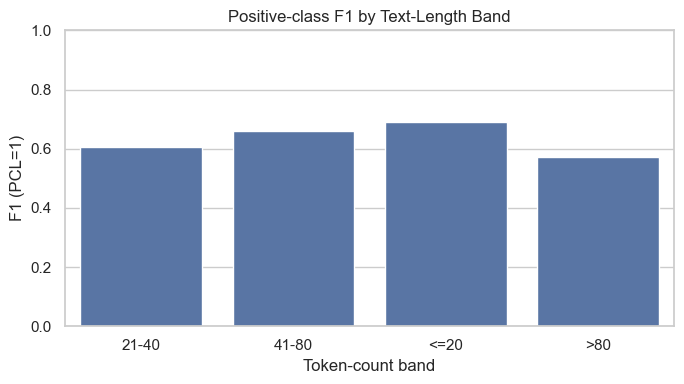

In [6]:
analysis_df["length_band"] = pd.cut(
    analysis_df["token_count"],
    bins=[0, 20, 40, 80, 10000],
    labels=["<=20", "21-40", "41-80", ">80"],
    right=True,
)

rows = []
for band, g in analysis_df.groupby("length_band", observed=True):
    y_t = g["label_official_bin"].to_numpy()
    y_p = g["pred"].to_numpy()
    rows.append(
        {
            "length_band": str(band),
            "samples": len(g),
            "positive_rate": round(g["label_official_bin"].mean(), 4),
            "f1_pos": round(f1_score(y_t, y_p, pos_label=1, zero_division=0), 4),
            "precision_pos": round(precision_score(y_t, y_p, pos_label=1, zero_division=0), 4),
            "recall_pos": round(recall_score(y_t, y_p, pos_label=1, zero_division=0), 4),
        }
    )

length_eval = pd.DataFrame(rows).sort_values("length_band")
display(length_eval)

plt.figure(figsize=(7,4))
sns.barplot(data=length_eval, x="length_band", y="f1_pos", color="#4c72b0")
plt.ylim(0, 1)
plt.title("Positive-class F1 by Text-Length Band")
plt.xlabel("Token-count band")
plt.ylabel("F1 (PCL=1)")
plt.tight_layout()
plt.show()
